In [5]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

# Load the dataset
dataset = load_dataset("cardiffnlp/tweet_eval", topics[0]) # change for different stance

# Convert to Pandas DataFrames
#combine train and validation into one dataframe for training and testing
df_train = pd.concat([dataset["train"].to_pandas(), dataset["validation"].to_pandas()])
df_test = dataset["test"].to_pandas()

# Display the data
print("Training samples:", len(df_train))
print("Test samples:", len(df_test))

display(df_train.head())

Training samples: 653
Test samples: 280


,text,label
0,we remind ourselves that love means to be will...,1
1,@user @user and most Islanders have different ...,0
2,"Life is #precious & so are babies, mothers, & ...",1
3,@user too many people are taking this to serio...,0
4,Dude i won a #freeshirt from @user ! I never w...,0


Number of tweets per stance:
label_name
Against           355
None / Neutral    177
Favor             121
Name: count, dtype: int64


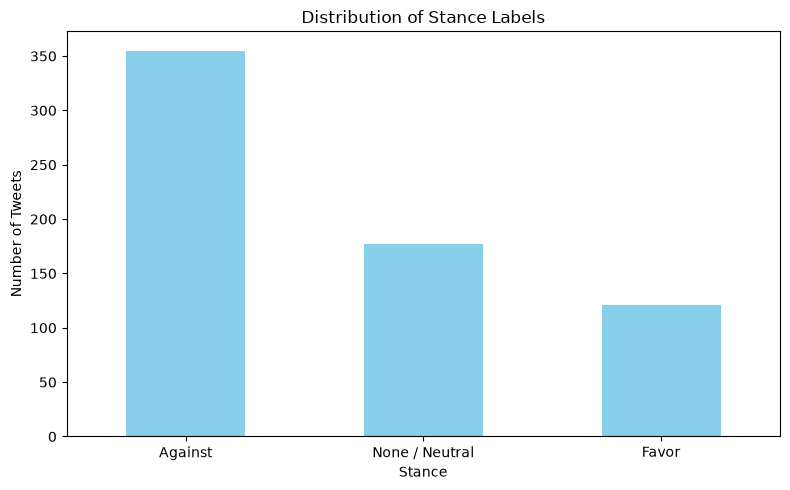

In [7]:
# Map numerical labels to stance names
label_names = {
    0: "None / Neutral",
    1: "Against",
    2: "Favor"
}

df_train["label_name"] = df_train["label"].map(label_names)

# Count tweets per stance
counts = df_train["label_name"].value_counts()

print("Number of tweets per stance:")
print(counts)

# Visualize the distribution
plt.figure(figsize=(8, 5))
counts.plot(kind="bar", color="skyblue")

plt.title("Distribution of Stance Labels")
plt.xlabel("Stance")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:
for topic in topics:
    dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    df_test = dataset["test"].to_pandas()
    counts = df_test["label"].value_counts()
    print(topic)
    print(f"Neutral: {counts.get(0, 0)}, Against: {counts.get(1, 0)}, Favor: {counts.get(2, 0)}")

stance_abortion
Neutral: 45, Against: 189, Favor: 46
stance_atheism
Neutral: 28, Against: 160, Favor: 32
stance_climate
Neutral: 35, Against: 11, Favor: 123
stance_feminist
Neutral: 44, Against: 183, Favor: 58
stance_hillary
Neutral: 78, Against: 172, Favor: 45
